# Demarcation and garimpo inside Indigenous lands

Lead 4 asks whether the gap between legal protection and control attracts garimpo into
Indigenous lands, especially while demarcation is pending
(`output/research/mining_economics_leads.md`, E16). This is a first pass on the stages.

- **Stages.** FUNAI dates each land's declaration (Justice Ministry) and homologation
  (presidential decree) (`protected_areas`).
- **Garimpo inside a land.** C11 garimpo (gold, unknown substance and other) from the
  river trenches. Each trench's pixels count in proportion to the share of its drainage
  polygon inside the land (`protected_areas --product trenches`), assuming garimpo is
  spread evenly within a trench.
- **Lands.** Indigenous lands whose centroid lies in the Legal Amazon, at any stage.
  Samples: all lands, and lands with an SGB gold occurrence inside.
- **Outcomes,** 1985–2019 (C11 steps in 2020):
  - the garimpo share of the land (pp);
  - any garimpo;
  - log(1 + garimpo hectares).
- **Stacked event studies** around each land's declaration and homologation year. For
  each event year from 1990 to 2012, the lands with the event that year are compared with
  the lands without it in the window (years −5 to +7). Episode × land and episode × year
  FE; SEs clustered by land.

Code: `src/analysis/garimpo_demarcation.py`. Tables go to `output/analysis/garimpo/demarcation/`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import garimpo_demarcation as D

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "demarcation"
OUT.mkdir(parents=True, exist_ok=True)

full = D.load_panel(years=(1985, 2025))
panel = full[full["year"].between(*D.YEARS)]
lands = panel.drop_duplicates("area_id")
print(len(lands), "Legal Amazon lands;", int((lands[D.GOLD] > 0).sum()), "with gold occurrences inside")
display(pd.DataFrame({event: lands[column].value_counts().sort_index() for event, column in D.EVENTS.items()})
        .loc[1985:2025].fillna(0).astype(int).T)

INFO:src.data.sources.biomes.preprocess:Excluding 2 non-municipality GADM ADM2 polygon(s) (e.g. lagoons).


407 Legal Amazon lands; 25 with gold occurrences inside


,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2023,2024,2025
declaration,0,2,0,2,1,0,16,27,19,0,2,11,3,16,6,12,17,10,0,5,3,9,10,6,6,5,1,1,2,1,1,9,1,1,0,4,2
homologation,2,5,2,0,7,5,72,4,8,1,6,24,22,29,0,2,16,0,15,21,7,8,3,1,8,1,3,7,1,0,7,2,0,1,4,1,4


**Reading the results.** Plenty of stage events, but mostly before garimpo grew.
- *Lands:* 407 Legal Amazon Indigenous lands; only 25 have an SGB gold occurrence inside.
- *Declarations:* 62 in 1991–93 and 75 in 1996–2002, then 0–10 a year.
- *Homologations:* 72 in 1991, 22–29 a year in 1996–98, and 15–21 in 2001 and 2003–04;
  few after 2012.

## 1. Garimpo by land and stage

In [2]:
hectares = full.pivot_table(index=["name", "stage", "year_declared", "year_homologated"], columns="year",
                            values="garimpo_pixels", dropna=False).mul(D.PIXEL_HA)
top = hectares[[1990, 2000, 2010, 2015, 2019, 2020, 2023, 2025]].sort_values(2019, ascending=False).head(15)
top.to_csv(OUT / "top_lands.csv")
display(top.round(0))
totals = full.groupby("year")["garimpo_pixels"].sum().mul(D.PIXEL_HA)
print("garimpo inside Legal Amazon Indigenous lands (ha):", totals.loc[[1985, 1990, 2000, 2010, 2015, 2019, 2020, 2025]].round(0).to_dict())
stages = D.stage_table(panel)
stages.to_csv(OUT / "stages.csv")
display(stages.round(0))

,,,year,1990,2000,2010,2015,2019,2020,2023,2025
name,stage,year_declared,year_homologated,,,,,,,,
Kayapó,Regularizada,NaN,1991,2946,4582,4713,5313,9217,1.158e+04,1.667e+04,1.844e+04
Munduruku,Regularizada,1998,2004,576,979,1180,1483,3538,5763,8221,8741
Yanomami,Regularizada,1991,1992,1412,1477,1487,1487,2041,2553,4891,5240
Tenharim do Igarapé Preto,Regularizada,1999,2004,1095,1107,1204,1235,1323,1360,1409,1454
Alto Turiaçu,Regularizada,1982,1982,530,531,548,556,577,650,887,957
Apyterewa,Regularizada,1992,2007,47,82,104,147,295,572,808,959
Sawré Muybu (Pimental),Declarada,2024,NaN,42,53,53,223,253,266,292,315
Uru-Eu-Wau-Wau,Regularizada,NaN,1991,44,50,120,189,209,245,301,343
Sararé,Regularizada,NaN,1985,0,169,171,177,180,181,732,3489


garimpo inside Legal Amazon Indigenous lands (ha): {1985: 2191.0, 1990: 6754.0, 2000: 9180.0, 2010: 9879.0, 2015: 11117.0, 2019: 17974.0, 2020: 23993.0, 2025: 41503.0}


,lands,garimpo_ha_2010,garimpo_ha_2019,lands_with_garimpo,change_ha
stage,,,,,
Declarada,27,59,258,3,199
Delimitada,22,21,22,1,1
Em Estudo,8,0,0,0,0
Encaminhada RI,13,0,0,0,0
Homologada,6,0,0,0,0
Regularizada,331,9800,1.769e+04,18,7894


**Reading the results.** Garimpo inside Indigenous lands sits in a few large lands that were
regularised long ago, and grows fast from 2019.
- *Total:* 2,191 ha (1985), 9,180 (2000), 9,879 (2010), 17,974 (2019) and 41,503 (2025;
  after the C11 2020 step).
- *Where:*
  - Kayapó: 4,713 ha (2010), 9,217 (2019), 18,440 (2025);
  - Munduruku: 1,180, 3,538, 8,741;
  - Yanomami: 1,487, 2,041, 5,240.

  The three hold 82% of garimpo inside lands in 2019, and Sararé jumps from 180 ha
  (2019) to 3,489 (2025). Kayapó's figure matches MapBiomas's published 2020 area (about
  11,500 ha), which supports the trench apportionment.
- *By current stage* (2019):
  - 18 of 331 regularised lands have garimpo, holding 98% of it (17,690 ha);
  - 3 of 27 declared lands have 258 ha, mostly Sawré Muybu;
  - delimited lands 22 ha; lands under study, homologated or awaiting registry, none.

  Pending lands are not where garimpo is.

## 2. Declaration and homologation

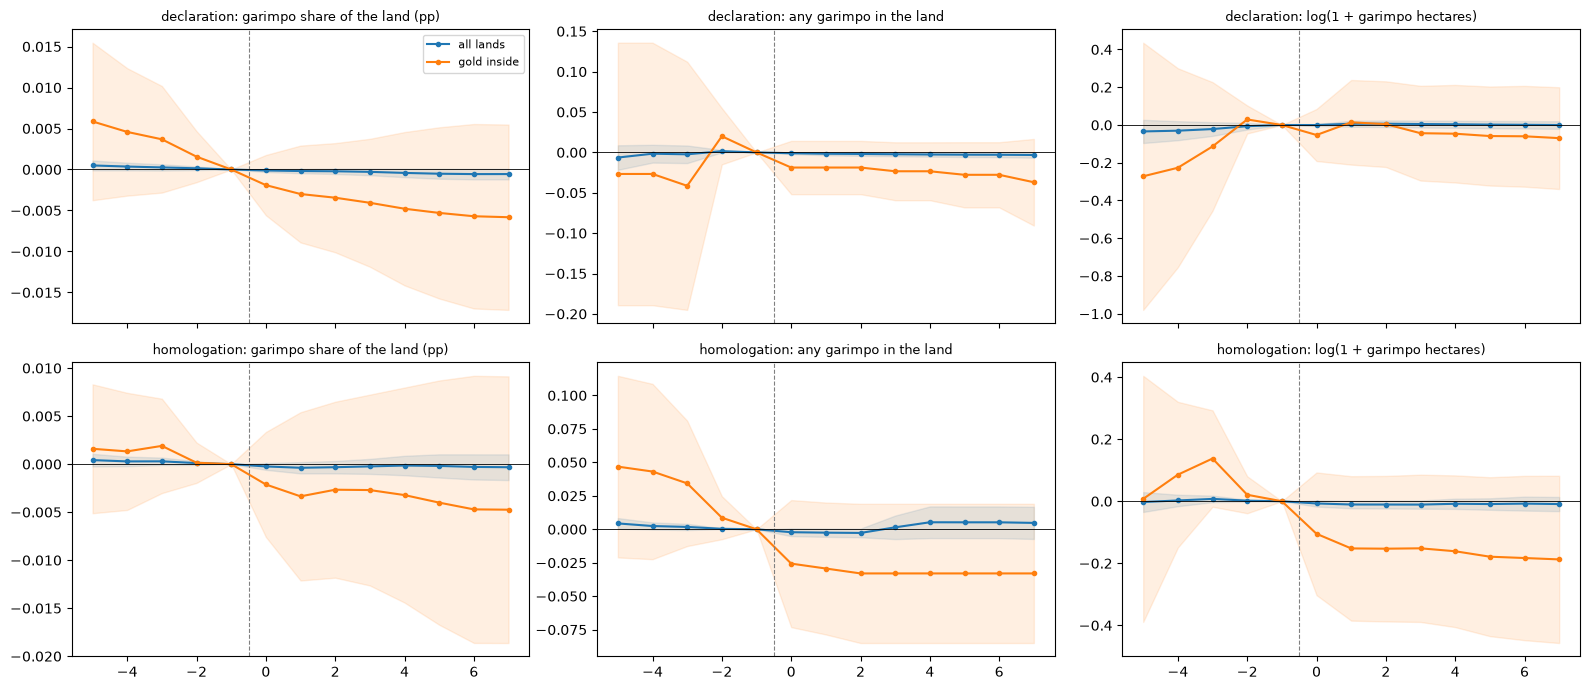

event   declaration                                                                       homologation                                                                      
sample    all lands                              gold inside                                 all lands                              gold inside                             
outcome  garimpo_pp any_garimpo log1p_garimpo_ha  garimpo_pp any_garimpo log1p_garimpo_ha   garimpo_pp any_garimpo log1p_garimpo_ha  garimpo_pp any_garimpo log1p_garimpo_ha
rel                                                                                                                                                                         
-5                0      -0.006           -0.034       0.006      -0.027           -0.272            0       0.004           -0.003       0.002       0.047            0.008
-4                0      -0.002            -0.03       0.005      -0.027           -0.227            0       0.002            0.002       0.001       0.043            0.086
-3                0      -0.002           -0.022       0.004      -0.041           -0.114            0       0.002            0.007       0.002       0.034            0.138
-2                0       0.002           -0.006       0.002        0.02            0.029            0           0            0.002           0       0.009            0.021
-1                0           0                0           0           0                0            0           0                0           0           0                0
 0               -0      -0.001               -0      -0.002      -0.019           -0.053           -0      -0.002           -0.007      -0.002      -0.026           -0.105
 1               -0      -0.002            0.007      -0.003      -0.019            0.014           -0      -0.003           -0.011      -0.003      -0.029           -0.152
 2               -0      -0.002            0.007      -0.003      -0.019            0.004           -0      -0.003           -0.011      -0.003      -0.033           -0.153
 3               -0      -0.002            0.005      -0.004      -0.023           -0.043           -0       0.001           -0.011      -0.003      -0.033           -0.152
 4               -0      -0.003            0.004      -0.005      -0.023           -0.046           -0       0.005           -0.008      -0.003      -0.033           -0.161
 5           -0.001      -0.003            0.002      -0.005      -0.028           -0.059           -0       0.005           -0.009      -0.004      -0.033           -0.179
 6           -0.001      -0.003            0.001      -0.006      -0.028            -0.06           -0       0.005           -0.008      -0.005      -0.033           -0.183
 7           -0.001      -0.003               -0      -0.006      -0.037            -0.07           -0       0.005           -0.009      -0.005      -0.033           -0.188

outcome                   garimpo_pp  any_garimpo  log1p_garimpo_ha
event        sample                                                
declaration  all lands        -0.001       -0.001             0.022
             gold inside      -0.007       -0.009             0.078
homologation all lands            -0            0            -0.011
             gold inside      -0.004       -0.058            -0.209

outcome                   garimpo_pp  any_garimpo  log1p_garimpo_ha
event        sample                                                
declaration  all lands         0.119        0.892             0.348
             gold inside       0.268         0.86             0.734
homologation all lands         0.382        0.996             0.337
             gold inside       0.509        0.117             0.206

,event,sample,n_cohorts,n_treated_lands,n_obs
0,declaration,all lands,20,185,84747
3,declaration,gold inside,8,12,2080
6,homologation,all lands,21,263,80522
9,homologation,gold inside,11,17,2613


In [3]:
SAMPLES = {"all lands": None, "gold inside": D.GOLD}
studies, pooled = [], []
for event in D.EVENTS:
    for name, sample in SAMPLES.items():
        stacked = D.stack(panel, event, sample=sample)
        for outcome in D.OUTCOMES:
            studies.append(D.event_study(stacked, outcome).assign(event=event, sample=name))
            pooled.append({"event": event, "sample": name, **D.pooled(stacked, outcome)})
studies = pd.concat(studies, ignore_index=True)
pooled = pd.DataFrame(pooled)
studies.to_csv(OUT / "event_studies.csv", index=False)
pooled.to_csv(OUT / "pooled.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for row, event in enumerate(D.EVENTS):
    for ax, outcome in zip(axes[row], D.OUTCOMES):
        for (name, color) in zip(SAMPLES, ("C0", "C1")):
            part = studies[(studies.event == event) & (studies["sample"] == name) & (studies.outcome == outcome)]
            ax.plot(part.rel, part.estimate, marker="o", ms=3, color=color, label=name)
            ax.fill_between(part.rel, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se, color=color,
                            alpha=0.12)
        ax.axvline(-0.5, color="grey", lw=0.8, ls="--")
        ax.axhline(0, color="black", lw=0.6)
        ax.set_title(f"{event}: {D.OUTCOMES[outcome]}", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(studies.pivot_table(index="rel", columns=["event", "sample", "outcome"], values="estimate", sort=False).round(3))
for value in ("estimate", "p"):
    display(pooled.pivot_table(index=["event", "sample"], columns="outcome", values=value, sort=False).round(3))
display(pooled[["event", "sample", "n_cohorts", "n_treated_lands", "n_obs"]].drop_duplicates(["event", "sample"]))

**Reading the results.** Neither declaration nor homologation moves garimpo inside a land.
- *All lands:*
  - the garimpo share and any garimpo stay within ±0.006 of the year before the event;
  - log hectares within ±0.04;
  - pooled effects −0.011 to +0.022 (p ≥ 0.12).
- *Lands with gold inside* (12–17 treated lands):
  - Before declaration, log garimpo hectares rise into the event (−0.27 at −5); after it
    they stay near −0.05.
  - After homologation, log hectares are −0.10 to −0.19 below the year before (pooled
    −0.21, p 0.21). The share of lands with any garimpo is −0.06 (p 0.12).
- *Power:* the stage events fall mostly in 1991–2004, when garimpo inside lands was small
  and concentrated, so these tests have little power for the lands that matter.
- *What it says:*
  - Garimpo inside Indigenous lands is not drawn to pending lands, and completing
    demarcation does not visibly push it out.
  - It concentrates in large, long-regularised lands with gold and river access
    (Kayapó, Munduruku, Yanomami), and it surges after 2019.
  - This points to protection without control, i.e. enforcement (lead 3), rather than
    legal status.